# Assignment 4

## Assignment topics:

**1. Classification: predict a categorical outcome.**

Datasets:

1.1. Telco Customer Churn - https://www.kaggle.com/blastchar/telco-customer-churn

1.2. Credit Card Fraud Detection - https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

1.3. Titanic dataset - https://www.kaggle.com/competitions/titanic

1.4. Heart Disease UCI - https://www.kaggle.com/search?q=heart+disease+UCI+in:datasets

**2. Regression: predict a continuous value.**

Datasets:

2.1. California Housing Prices - https://www.kaggle.com/camnugent/california-housing-prices

2.2. House Prices (predict residential property sale prices using numerous property attributes) - https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

2.3. Used Car Price Prediction - https://www.kaggle.com/search?q=used+car+price+prediction+in:datasets

2.4. Your own data collected: on the campus of Chernivtsi National Uni (math faculty or other), in Chernivtsi city, etc., via API or web-scraped, relevant for our region.

**3. Time series forecasting: predict future values.**

Datasets:

3.1. Store sales forecast - https://www.kaggle.com/competitions/store-sales-time-series-forecasting

3.2. NYC tax trip data (predict hourly demand) - https://www.kaggle.com/search?q=NYC+Taxi+Trip+Data+in:datasets

3.3. Bitcoin historic data (price forecasting) - https://www.kaggle.com/search?q=Bitcoin+Historical+Data+in:datasets

3.4. Electricity consumption (predict demand) - https://www.kaggle.com/search?q=electricity+consumption+in:datasets

**4. NLP: analyze and classify text.**

Datasets:

4.1. IMDB dataset (sentiment analysis) - https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

4.2. SMS Spam Collection (spam classification) - https://www.kaggle.com/uciml/sms-spam-collection-dataset

4.3. Emotion Detection from Text (multiclass classification) - https://www.kaggle.com/datasets/pashupatigupta/emotion-detection-from-text

4.4. Your own data collected: on the campus of Chernivtsi National Uni (math faculty or other), in Chernivtsi city, etc., via API or web-scraped, relevant for our region.

**5. Recommendation systems: recommend products or content.**

Datasets:

5.1. MovieLens 20M (movie recommendation) - https://www.kaggle.com/grouplens/movielens-20m-dataset

5.2. Instacart Market Basket Analysis (product recommendation) - https://www.kaggle.com/c/instacart-market-basket-analysis

5.3. Goodbooks-10k (books recommendation) - https://www.kaggle.com/datasets/zygmunt/goodbooks-10k

5.4. Your own data collected: on the campus of Chernivtsi National Uni (math faculty or other), in Chernivtsi city, etc., via API or web-scraped, relevant for our region.

**6. Clustering: discover hidden groups.**

Datasets:

6.1. Online Retail II (customer segmentation) - https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci

6.2. Mall Customer Segmentation - https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

6.3. Wholesale Customers Dataset (customer segmentation) - https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set

6.4. Your own data collected: on the campus of Chernivtsi National Uni (math faculty or other), in Chernivtsi city, etc., via API or web-scraped, relevant for our region.

**7. Anomaly detection: identify unusual observations.**

Datasets:

7.1. Credit Card Fraud Detection - https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

7.2. Synthetic Financial Datasets for Fraud Detection - https://www.kaggle.com/datasets/ealaxi/paysim1

7.3. Network Intrusion Detection - https://www.kaggle.com/search?q=network+intrusion+detection+in:datasets

7.4. Your own data collected: on the campus of Chernivtsi National Uni (math faculty or other), in Chernivtsi city, etc., via API or web-scraped, relevant for our region.

## Exploratory Data Analysis (EDA)

Describe the dataset, its origin, structure, and variables. Calculate descriptive statistics (mean, median, standard deviation, quartiles). Investigate missing values, duplicates, and outliers. Analyze distributions and relationships between variables. Create at least 5 meaningful visualizations (employ dimensionality reduction where fit). Identify potential correlations and dependencies. Formulate at least 2 research questions or hypotheses. Explain data preprocessing decisions.

# Credit Card Fraud Detection

## Походження та структура датасету
**Джерело:** спільне дослідження платіжного процесора **Worldline** та групи машинного навчання **ULB (Université Libre de Bruxelles)**, опубліковане на Kaggle (`mlg-ulb/creditcardfraud`).
**Період спостереження:** 2 доби (вересень 2013 року), транзакції європейських власників карток (`172 792` секунди $\approx 48$ годин).
**Обсяг вибірки:** `284 807` транзакцій та `31` ознака.
**Специфіка задачі:** екстремальний дисбаланс класів (`0,1727%` шахрайських операцій), що вимагає спеціальних методів валідації, масштабування та вибору метрик (`PR-AUC` замість `Accuracy`).

## Опис змінних та обґрунтування їхньої трансформації

| Змінна | Тип | Опис та аналітичне обґрунтування |
| :--- | :--- | :--- |
| **`Time`** | `float64` | Кількість секунд від першої транзакції у вибірці `[0; 172 792]`. Відображає добову циклічність активності користувачів, проте приховує календарну дату та день тижня. |
| **`V1` – `V28`** | `float64` | 28 головних компонент, отриманих через **PCA** (Principal Component Analysis). Оригінальні бізнес-поля (мерчант, геолокація, MCC-код, ID картки) приховані для дотримання банківської таємниці та вимог **GDPR / PCI DSS**. Компоненти впорядковані за спаданням дисперсії. |
| **`Amount`** | `float64` | Сума транзакції в євро (EUR). **Навмисно виключена з PCA**, щоб зберегти фізичний зміст платежу та забезпечити побудову вартісно-чутливих моделей (*cost-sensitive learning*), де ціна помилки залежить від суми списання. |
| **`Class`** | `int64` | Цільова бінарна змінна: `0` — легітимна операція, `1` — підтверджене шахрайство. |

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import RobustScaler
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import StratifiedKFold

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 35)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [4]:
import kagglehub

# Завантаження актуальної версії датасету безпосередньо з Kaggle
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))
print(f"Завантажено файл: {csv_file} | Розмірність: {df.shape}")

100%|██████████| 66.0M/66.0M [00:10<00:00, 6.77MB/s]

Extracting files...


Path to dataset files: C:\Users\Олександр\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3
Завантажено файл: creditcard.csv | Розмірність: (284807, 31)


In [5]:
display(df.head(5))
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

## Аналіз дисбалансу цільової змінної `Class`
Перед будь-якими статистичними тестами необхідно оцінити співвідношення класів. За коефіцієнта дисбалансу `~1 : 578` стандартна точність (`Accuracy`) є неінформативною (константний прогноз `0` дає `99,83%`), а розбиття вибірки без стратифікації може спотворити частку позитивного класу.

In [6]:
class_counts = df["Class"].value_counts()
class_pct = df["Class"].value_counts(normalize=True) * 100
imbalance_ratio = class_counts[0] / class_counts[1]

summary_class = pd.DataFrame({
    "Кількість": class_counts,
    "Частка (%)": class_pct
})
display(summary_class)
print(f"Коефіцієнт дисбалансу (Class 0 : Class 1) = {imbalance_ratio:.2f} : 1")

,Кількість,Частка (%)
Class,,
0,284315,99.8273
1,492,0.1727


Коефіцієнт дисбалансу (Class 0 : Class 1) = 577.88 : 1


## Описова статистика та порівняння класів
Для асиметричних фінансових даних середнє арифметичне (`Mean`) зміщується під впливом великих платежів, тому обов'язково розраховуються робастні метрики: **медіана (`50%`)**, **квартилі (`Q1`, `Q3`)** та **міжквартильний розмах (`IQR = Q3 - Q1`)**.

In [7]:
desc = df.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc.rename(columns={"50%": "median", "25%": "Q1", "75%": "Q3"}, inplace=True)
desc["IQR"] = desc["Q3"] - desc["Q1"]
display(desc)

,mean,std,min,Q1,median,Q3,max,IQR
Time,94813.8596,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000,85119.0000
V1,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549,2.2360
V2,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577,1.4023
V3,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826,1.9176
V4,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753,1.5920
V5,0.0000,1.3802,-113.7433,-0.6916,-0.0543,0.6119,34.8017,1.3035
V6,0.0000,1.3323,-26.1605,-0.7683,-0.2742,0.3986,73.3016,1.1669
V7,-0.0000,1.2371,-43.5572,-0.5541,0.0401,0.5704,120.5895,1.1245
V8,0.0000,1.1944,-73.2167,-0.2086,0.0224,0.3273,20.0072,0.5360
V9,-0.0000,1.0986,-13.4341,-0.6431,-0.0514,0.5971,15.5950,1.2402


In [8]:
for col in ["Amount", "Time"]:
    print(f"=== Статистика для {col} за класами ===")
    grouped = df.groupby("Class")[col].agg(
        mean="mean",
        std="std",
        min="min",
        Q1=lambda s: s.quantile(0.25),
        median="median",
        Q3=lambda s: s.quantile(0.75),
        max="max",
        IQR=lambda s: s.quantile(0.75) - s.quantile(0.25)
    )
    display(grouped)

=== Статистика для Amount за класами ===


,mean,std,min,Q1,median,Q3,max,IQR
Class,,,,,,,,
0,88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,25691.1600,71.4000
1,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,2125.8700,104.8900


=== Статистика для Time за класами ===


,mean,std,min,Q1,median,Q3,max,IQR
Class,,,,,,,,
0,94838.2023,47484.0158,0.0000,54230.0000,84711.0000,139333.0000,172792.0000,85103.0000
1,80746.8069,47835.3651,406.0000,41241.5000,75568.5000,128483.0000,170348.0000,87241.5000


## Перевірка якості даних: пропуски, дублікати та викиди
* **Пропуски та нульові платежі:** Окрім технічних `NaN`, у платіжних даних важливо перевірити `Amount == 0.00` (*Zero-Dollar Authorization* — запити верифікації активності картки, якими часто користуються шахраї).
* **Дублікати:** Через дискретизацію часу до секунд та анонімізацію ID терміналів повторні запити шлюзу виглядають як ідентичні рядки. Їх **необхідно видалити до розбиття на train/test**, щоб уникнути витоку даних (*Data Leakage*).
* **Викиди:** У задачах виявлення шахрайства екстремальні відхилення в `V1`–`V28` та `Amount` є не шумом, а носіями сигналу про аномалію, тому їх **не можна видаляти чи обрізати**.

In [9]:
total_nans = df.isna().sum().sum()
zero_amount_stats = df.groupby("Class")["Amount"].apply(lambda s: (s == 0).sum())
zero_amount_pct = df.groupby("Class")["Amount"].apply(lambda s: (s == 0).mean() * 100)

print(f"Загальна кількість технічних пропусків (NaN): {total_nans}")
display(pd.DataFrame({
    "Кількість транзакцій з Amount == 0": zero_amount_stats,
    "Частка в класі (%)": zero_amount_pct
}))

Загальна кількість технічних пропусків (NaN): 0


,Кількість транзакцій з Amount == 0,Частка в класі (%)
Class,,
0,1798,0.6324
1,27,5.4878


In [10]:
duplicates_by_class = df[df.duplicated(keep="first")]["Class"].value_counts()
print(f"Усього точних дублікатів: {df.duplicated().sum()} ({df.duplicated().mean()*100:.3f}%)")
print("Розподіл дублікатів за класами:\n", duplicates_by_class)

# Видаляємо дублікати перед подальшим аналізом та візуалізацією
df = df.drop_duplicates().reset_index(drop=True)
print(f"Розмірність після очищення дублікатів: {df.shape}")

Усього точних дублікатів: 1081 (0.380%)
Розподіл дублікатів за класами:
 Class
0    1062
1      19
Name: count, dtype: int64
Розмірність після очищення дублікатів: (283726, 31)


In [11]:
q1_amt, q3_amt = df["Amount"].quantile([0.25, 0.75])
iqr_amt = q3_amt - q1_amt
upper_fence = q3_amt + 1.5 * iqr_amt
outliers_amt = (df["Amount"] > upper_fence).sum()

print(f"Skewness (асиметрія) Amount: {df['Amount'].skew():.2f}")
print(f"Kurtosis (ексцес) Amount:    {df['Amount'].kurt():.2f}")
print(f"Верхня межа Тьюкі для Amount: {upper_fence:.2f} EUR")
print(f"Кількість викидів за IQR:     {outliers_amt:,} ({outliers_amt / len(df) * 100:.2f}%)")

Skewness (асиметрія) Amount: 16.98
Kurtosis (ексцес) Amount:    844.47
Верхня межа Тьюкі для Amount: 185.38 EUR
Кількість викидів за IQR:     31,685 (11.17%)


## Візуальний аналіз розподілів, кореляцій та зменшення розмірності
Кожна візуалізація нижче розв'язує окрему аналітичну задачу:
1. **Добова циклічність (`Hour`):** виявлення нічного сплеску відносного ризику шахрайства на фоні падіння трафіку легітимних клієнтів.
2. **Violin + Boxplot топ-8 PCA-компонент:** оцінка зміщення медіан та мультимодальності хвостів найбільш дискримінативних ознак.
3. **Логарифмічний розподіл $\log_{10}(\text{Amount} + 1)$ та ECDF:** усунення впливу надвисокого ексцесу (`845`) для аналізу патерну мікроплатежів.
4. **Умовна кореляційна матриця (`Class == 1`):** виявлення синхронної поведінки компонент усередині шахрайського класу (де порушується глобальна ортогональність PCA).
5. **2D-проєкція `t-SNE`:** нелінійне зменшення розмірності 30 ознак для перевірки локальної кластеризації шахрайських операцій.
6. **Фазовий портрет (`V14` vs `V17`) + `Isolation Forest`:** перевірка роздільності класів у просторі двох найсильніших предикторів.

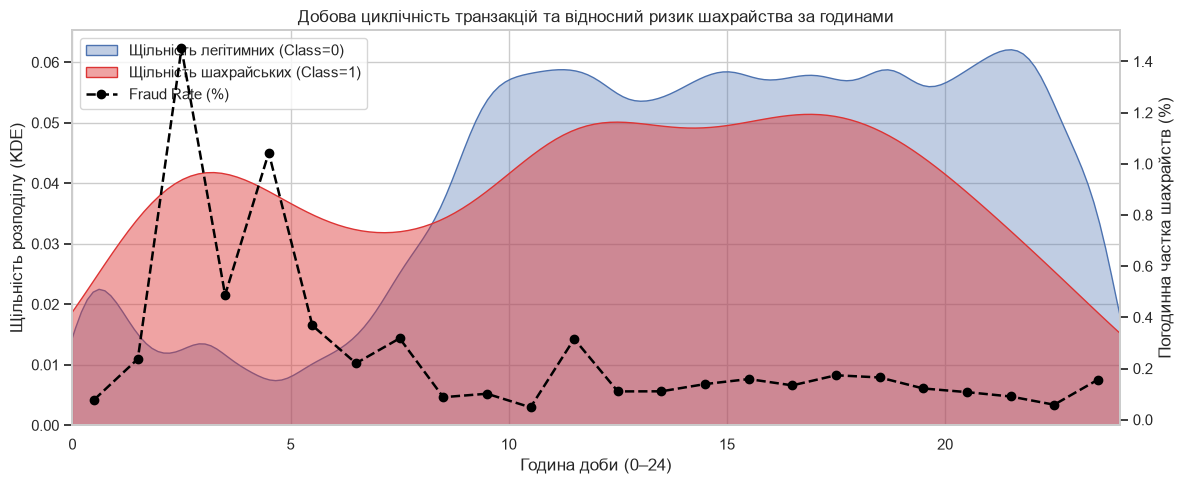

In [12]:
df["Hour"] = (df["Time"] / 3600.0) % 24.0
df["Hour_bin"] = np.floor(df["Hour"]).astype(int)

hourly_fraud_rate = df.groupby("Hour_bin")["Class"].mean() * 100

fig, ax1 = plt.subplots(figsize=(12, 5))
sns.kdeplot(data=df[df["Class"] == 0], x="Hour", fill=True, alpha=0.35, color="#4C72B0", label="Щільність легітимних (Class=0)", ax=ax1)
sns.kdeplot(data=df[df["Class"] == 1], x="Hour", fill=True, alpha=0.45, color="#DD3434", label="Щільність шахрайських (Class=1)", ax=ax1)
ax1.set_xlim(0, 24)
ax1.set_xlabel("Година доби (0–24)")
ax1.set_ylabel("Щільність розподілу (KDE)")

ax2 = ax1.twinx()
ax2.plot(hourly_fraud_rate.index + 0.5, hourly_fraud_rate.values, color="black", marker="o", linestyle="--", linewidth=1.8, label="Fraud Rate (%)")
ax2.set_ylabel("Погодинна частка шахрайств (%)")
ax2.grid(False)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")
plt.title("Добова циклічність транзакцій та відносний ризик шахрайства за годинами")
plt.tight_layout()
plt.show()

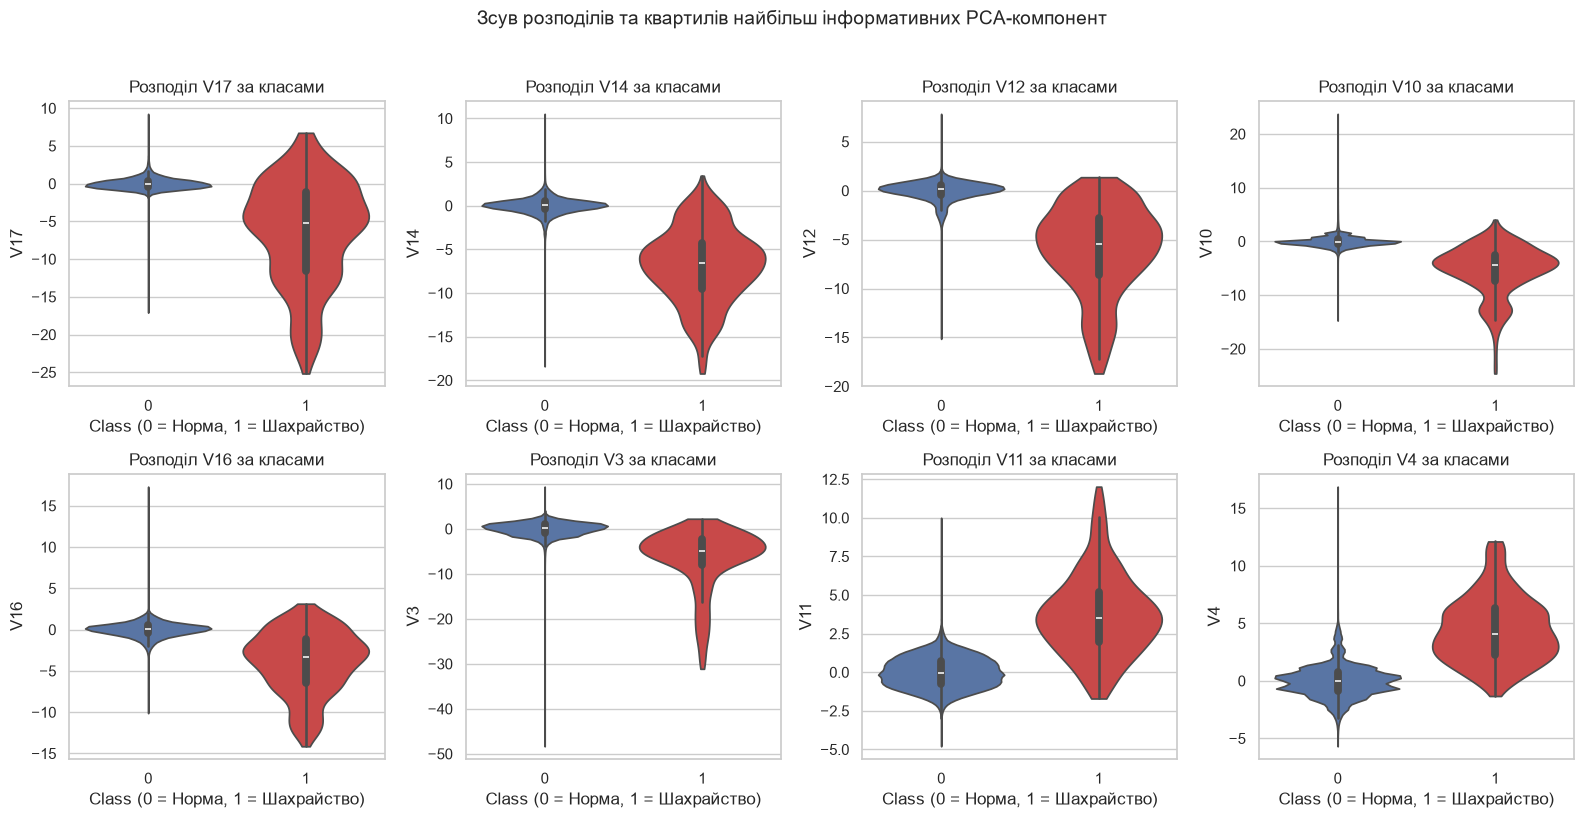

In [13]:
top_pca = ["V17", "V14", "V12", "V10", "V16", "V3", "V11", "V4"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, col in enumerate(top_pca):
    ax = axes[idx // 4, idx % 4]
    sns.violinplot(
        data=df, x="Class", y=col, hue="Class",
        palette={0: "#4C72B0", 1: "#DD3434"},
        inner="box", cut=0, legend=False, ax=ax
    )
    ax.set_title(f"Розподіл {col} за класами")
    ax.set_xlabel("Class (0 = Норма, 1 = Шахрайство)")

plt.suptitle("Зсув розподілів та квартилів найбільш інформативних PCA-компонент", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

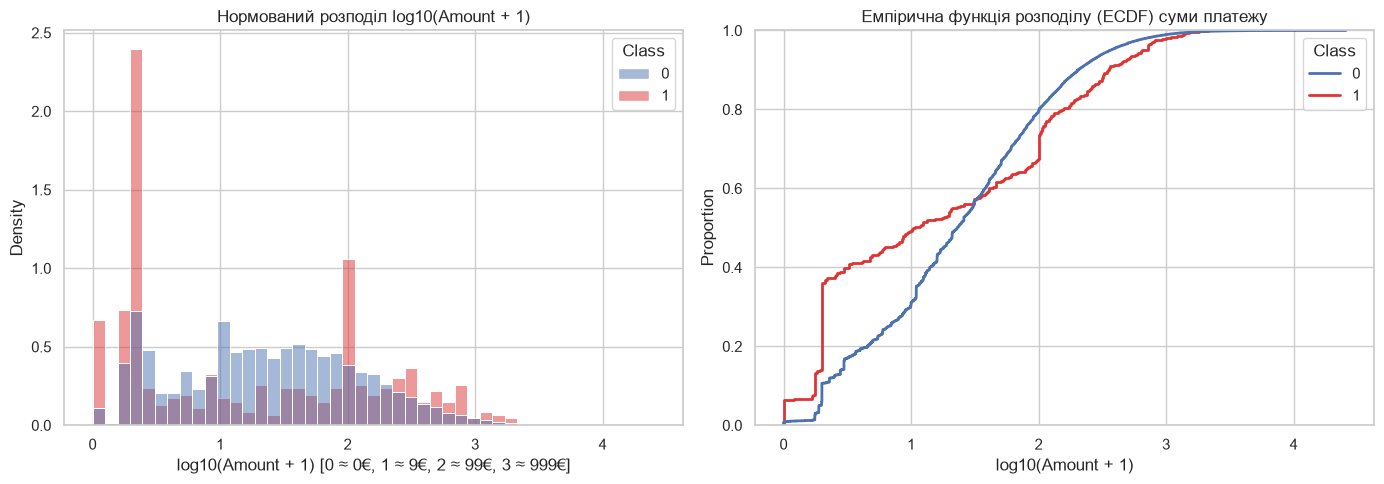

In [14]:
df["Log_Amount"] = np.log10(df["Amount"] + 1.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="Log_Amount", hue="Class",
    stat="density", common_norm=False, bins=45,
    palette={0: "#4C72B0", 1: "#DD3434"}, ax=ax1
)
ax1.set_title("Нормований розподіл log10(Amount + 1)")
ax1.set_xlabel("log10(Amount + 1) [0 ≈ 0€, 1 ≈ 9€, 2 ≈ 99€, 3 ≈ 999€]")

sns.ecdfplot(
    data=df, x="Log_Amount", hue="Class",
    palette={0: "#4C72B0", 1: "#DD3434"}, linewidth=2, ax=ax2
)
ax2.set_title("Емпірична функція розподілу (ECDF) суми платежу")
ax2.set_xlabel("log10(Amount + 1)")

plt.tight_layout()
plt.show()

In [15]:
feature_cols = ["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]
corr_with_class = df[feature_cols].corrwith(df["Class"]).sort_values()

corr_summary = pd.DataFrame({
    "Кореляція Пірсона з Class": corr_with_class,
    "Абсолютне значення |r|": corr_with_class.abs()
}).sort_values("Абсолютне значення |r|", ascending=False)

display(corr_summary.head(12))

,Кореляція Пірсона з Class,Абсолютне значення |r|
V17,-0.3135,0.3135
V14,-0.2934,0.2934
V12,-0.2507,0.2507
V10,-0.2070,0.2070
V16,-0.1872,0.1872
V3,-0.1823,0.1823
V7,-0.1723,0.1723
V11,0.1491,0.1491
V4,0.1293,0.1293
V18,-0.1053,0.1053


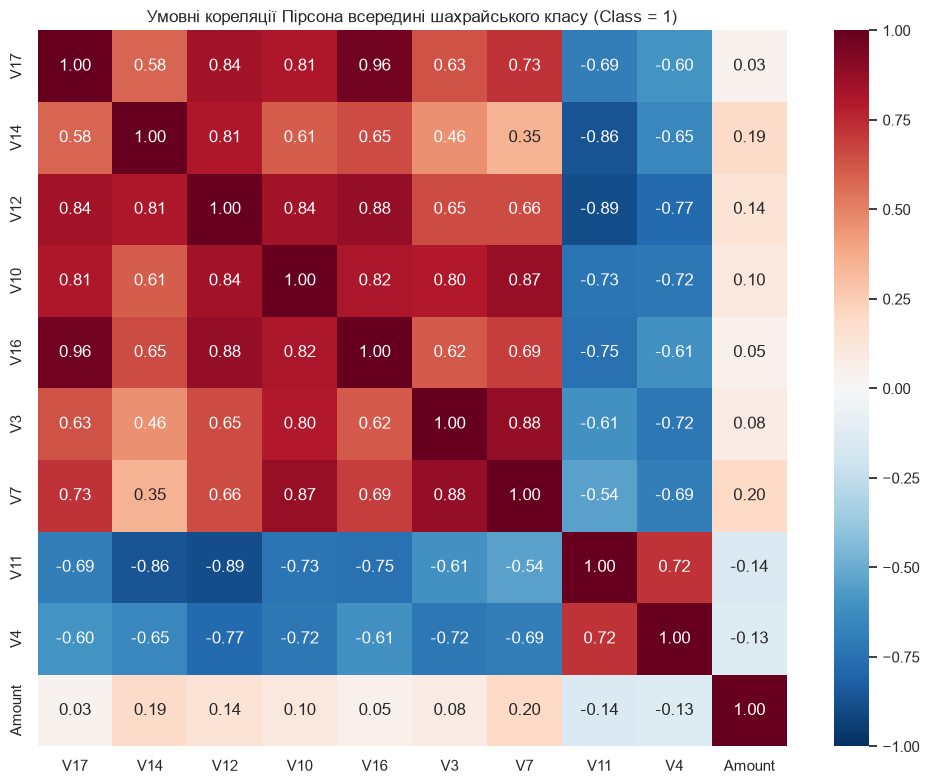

In [16]:
selected_vars = ["V17", "V14", "V12", "V10", "V16", "V3", "V7", "V11", "V4", "Amount"]
fraud_corr = df[df["Class"] == 1][selected_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(fraud_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Умовні кореляції Пірсона всередині шахрайського класу (Class = 1)")
plt.tight_layout()
plt.show()

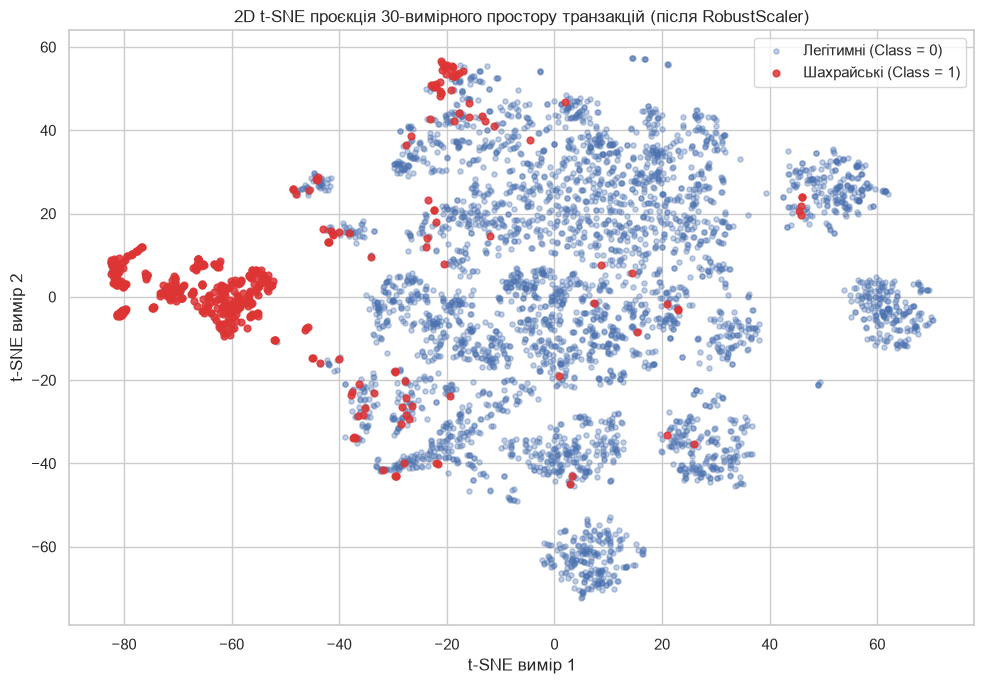

In [17]:
# Формуємо стратифіковану підвибірку: усі шахрайства + 4000 випадкових легітимних транзакцій
fraud_df = df[df["Class"] == 1]
legit_sample = df[df["Class"] == 0].sample(n=4000, random_state=42)
sub_df = pd.concat([fraud_df, legit_sample], ignore_index=True)

tsne_features = [f"V{i}" for i in range(1, 29)] + ["Amount", "Hour"]
X_scaled = RobustScaler().fit_transform(sub_df[tsne_features])

tsne_2d = TSNE(
    n_components=2, perplexity=40, random_state=42,
    init="pca", learning_rate="auto"
).fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
plt.scatter(tsne_2d[sub_df["Class"] == 0, 0], tsne_2d[sub_df["Class"] == 0, 1], c="#4C72B0", alpha=0.35, s=14, label="Легітимні (Class = 0)")
plt.scatter(tsne_2d[sub_df["Class"] == 1, 0], tsne_2d[sub_df["Class"] == 1, 1], c="#DD3434", alpha=0.85, s=24, label="Шахрайські (Class = 1)")
plt.title("2D t-SNE проєкція 30-вимірного простору транзакцій (після RobustScaler)")
plt.xlabel("t-SNE вимір 1")
plt.ylabel("t-SNE вимір 2")
plt.legend()
plt.tight_layout()
plt.show()

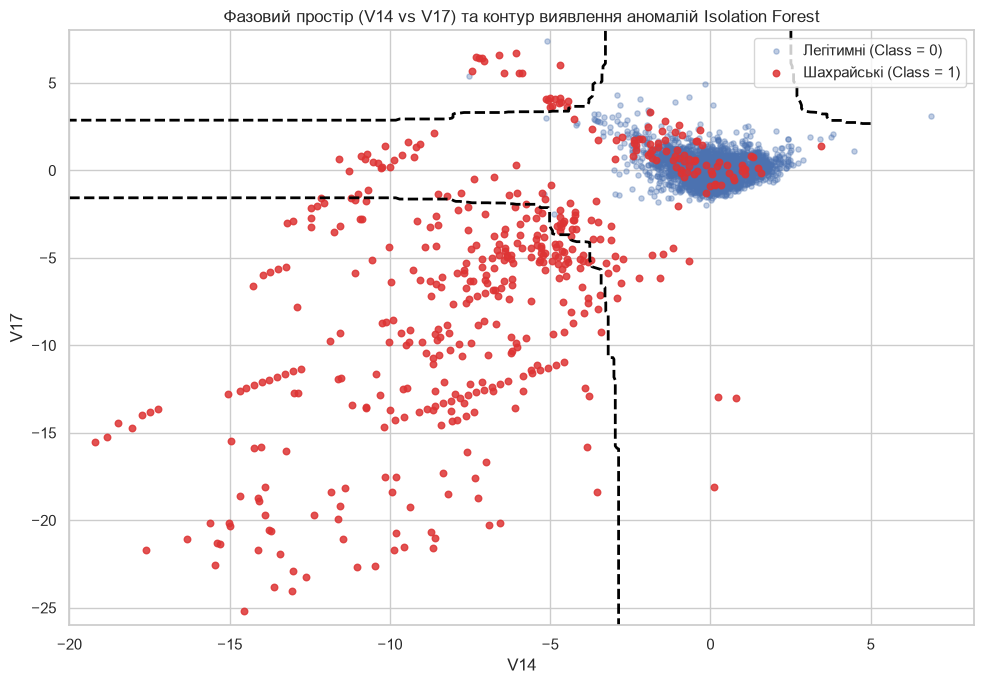

In [18]:
iso = IsolationForest(contamination=0.002, random_state=42)
iso.fit(df[["V14", "V17"]].to_numpy())

xx, yy = np.meshgrid(np.linspace(-20, 5, 200), np.linspace(-26, 8, 200))
Z = iso.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 7))
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors="black", linestyles="--")
plt.scatter(legit_sample["V14"], legit_sample["V17"], c="#4C72B0", alpha=0.35, s=14, label="Легітимні (Class = 0)")
plt.scatter(fraud_df["V14"], fraud_df["V17"], c="#DD3434", alpha=0.85, s=22, label="Шахрайські (Class = 1)")
plt.xlabel("V14")
plt.ylabel("V17")
plt.title("Фазовий простір (V14 vs V17) та контур виявлення аномалій Isolation Forest")
plt.legend()
plt.tight_layout()
plt.show()

## Дослідницькі питання та статистичні гіпотези

1. **Гіпотеза 1 (Добова асиметрія шахрайської активності):**
   * *Питання:* Чи відрізняється розподіл часу доби здійснення транзакцій для шахраїв та легітимних клієнтів?
   * $H_0$: Функції розподілу години доби однакові для обох класів ($F_0(\text{Hour}) = F_1(\text{Hour})$).
   * $H_1$: Розподіли статистично значуще відрізняються ($F_0(\text{Hour}) \neq F_1(\text{Hour})$), а відносний ризик зростає в нічний час.
   * *Метод перевірки:* двовибірковий **критерій Колмогорова–Смірнова (KS-test)** (непараметричний, не потребує нормальності).

2. **Гіпотеза 2 (Тактика тестування карток мікроплатежами — Card Testing):**
   * *Питання:* Чи використовують зловмисники масові мікротранзакції ($\le 1,00\text{ €}$) для перевірки валідності картки?
   * $H_0$: Медіанна сума та частка платежів $\le 1,00\text{ €}$ у класах `0` і `1` не відрізняються.
   * $H_1$: Медіанна сума в класі `1` є нижчою, а частка мікроплатежів ($\le 1,00\text{ €}$) — суттєво вищою.
   * *Метод перевірки:* **U-критерій Манна–Вітні** для порівняння медіанних зсувів та **точний тест Фішера** для частот мікротранзакцій.

In [19]:
amt_0 = df[df["Class"] == 0]["Amount"]
amt_1 = df[df["Class"] == 1]["Amount"]
hr_0 = df[df["Class"] == 0]["Hour"]
hr_1 = df[df["Class"] == 1]["Hour"]

# 1. Тест Колмогорова-Смірнова для добового розподілу Hour
ks_stat, ks_p = stats.ks_2samp(hr_0, hr_1)

# 2. U-критерій Манна-Вітні для суми платежу Amount
u_stat, u_p = stats.mannwhitneyu(amt_0, amt_1, alternative="two-sided")

# 3. Точний тест Фішера для частки мікроплатежів (Amount <= 1.00 EUR)
table_micro = [
    [(amt_1 <= 1.0).sum(), (amt_1 > 1.0).sum()],
    [(amt_0 <= 1.0).sum(), (amt_0 > 1.0).sum()]
]
odds_ratio, fisher_p = stats.fisher_exact(table_micro, alternative="greater")

print(f"KS-test (Hour):          statistic = {ks_stat:.4f}, p-value = {ks_p:.3e}")
print(f"Mann-Whitney (Amount):   U = {u_stat:.0f}, p-value = {u_p:.3e}")
print(f"Fisher test (<= 1 EUR):  Odds Ratio = {odds_ratio:.2f}, p-value = {fisher_p:.3e}")

KS-test (Hour):          statistic = 0.1911, p-value = 1.446e-15
Mann-Whitney (Amount):   U = 74461540, p-value = 2.686e-05
Fisher test (<= 1 EUR):  Odds Ratio = 4.75, p-value = 1.262e-48


## Обґрунтування пайплайну попередньої обробки даних (Data Preprocessing)

1. **Видалення точних дублікатів до розбиття вибірки:** усуває витік даних (*Data Leakage*) між навчальною та валідаційною вибірками.
2. **Масштабування `Amount` через `RobustScaler`:** на відміну від `StandardScaler` та `MinMaxScaler`, він спирається на медіану та `IQR`, не спотворюючи масштаб через викиди до `25 691 €`.
3. **Циклічне кодування часу (`Hour_sin`, `Hour_cos`):** зберігає неперервність переходу між `23:59` та `00:01` для лінійних моделей і нейронних мереж.
4. **Доменні ознаки ризику (`Log_Amount`, `Is_Zero_Amount`, `Is_Micro_Amount`):** явно кодують виявлений під час EDA патерн перевірки карток нульовими та мікроплатежами (`<= 1 €`).
5. **Збереження викидів та стратифікована крос-валідація (`StratifiedKFold`):** фіксує точну частку рідкісного класу (`0,167%`) у кожному фолді без втрати аномальних сигналів.

In [20]:
df_prep = df.copy()

# 1. Циклічне кодування часу доби
df_prep["Hour_sin"] = np.sin(2 * np.pi * df_prep["Hour"] / 24.0)
df_prep["Hour_cos"] = np.cos(2 * np.pi * df_prep["Hour"] / 24.0)

# 2. Доменні індикатори суми
df_prep["Is_Zero_Amount"] = (df_prep["Amount"] == 0).astype(int)
df_prep["Is_Micro_Amount"] = (df_prep["Amount"] <= 1.0).astype(int)

# 3. Робастне масштабування Amount (fit виконується лише на train-фолді під час CV)
feature_list = [f"V{i}" for i in range(1, 29)] + [
    "Amount", "Log_Amount", "Hour_sin", "Hour_cos", "Is_Zero_Amount", "Is_Micro_Amount"
]
X = df_prep[feature_list]
y = df_prep["Class"]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    scaler = RobustScaler()
    X_train_amt = scaler.fit_transform(X.iloc[train_idx][["Amount"]])
    X_val_amt = scaler.transform(X.iloc[val_idx][["Amount"]])
    print(f"Fold {fold}: Train = {len(train_idx):,} (Fraud = {y.iloc[train_idx].sum()}) | Val = {len(val_idx):,} (Fraud = {y.iloc[val_idx].sum()})")

Fold 1: Train = 226,980 (Fraud = 378) | Val = 56,746 (Fraud = 95)
Fold 2: Train = 226,981 (Fraud = 379) | Val = 56,745 (Fraud = 94)
Fold 3: Train = 226,981 (Fraud = 379) | Val = 56,745 (Fraud = 94)
Fold 4: Train = 226,981 (Fraud = 378) | Val = 56,745 (Fraud = 95)
Fold 5: Train = 226,981 (Fraud = 378) | Val = 56,745 (Fraud = 95)


## Machine Learning (and/or other algorithm aplication)

Define the ML problem formally. Prepare the dataset for model training. Perform feature engineering where appropriate. Select at least 3 different ML algorithms. Train and validate the models. Perform hyperparameter optimization for at least one model. Explain the model selection process.

For certain tasks (recommendation systems, TF-IDF nlp) use different, non-ML algorithms (at least 2 different). 

Compare algorithms using appropriate metrics: accuracy, F1 (classification tasks), MSE (regression/ ts prediction), etc. Visualize models performance. Identify strengths and weaknesses of each algorithm.

In [ ]:
# ML section

## Hypothesis Testing

Compare two ML algorithms. The following statistical hypotheses recommended:

- $H_0$: There is no statistically significant difference in the performance of Random Forest and XGBoost.
- $H_1$: There is a statistically significant difference in their performance.

In [ ]:
# Hypothesis testing section